# Practical 11 – AdaBoost Classification

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay


In [2]:
raw = load_breast_cancer(as_frame=True)
X = raw.data
y = raw.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


In [3]:
def evaluate(name, model):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    scores = {'Accuracy': accuracy_score(y_test, pred), 'Precision': precision_score(y_test, pred, pos_label=0), 'Recall': recall_score(y_test, pred, pos_label=0), 'F1': f1_score(y_test, pred, pos_label=0)}
    print(name, scores)
    print(classification_report(y_test, pred, target_names=['Malignant', 'Benign']))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=[0, 1], display_labels=['Malignant', 'Benign'])
    plt.title(name)
    plt.show()
    return scores


C:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:519: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


AdaBoost {'Accuracy': 0.956140350877193, 'Precision': 0.9743589743589743, 'Recall': 0.9047619047619048, 'F1': 0.9382716049382716}
              precision    recall  f1-score   support

   Malignant       0.97      0.90      0.94        42
      Benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



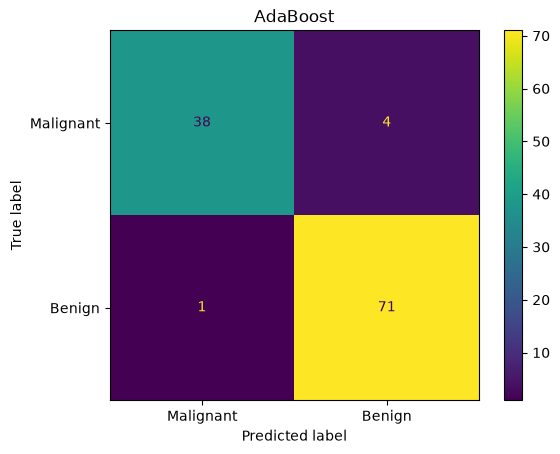

Text(0, 0.5, 'Weight')

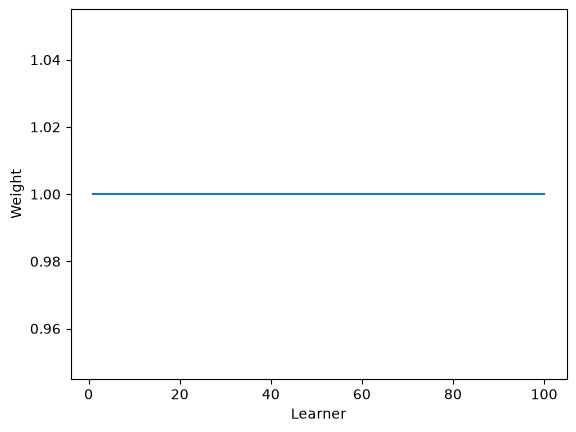

In [6]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
model = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1, random_state=42), n_estimators=100, learning_rate=0.5, random_state=42)
evaluate('AdaBoost', model)
plt.plot(range(1, len(model.estimator_weights_) + 1), model.estimator_weights_)
plt.xlabel('Learner')
plt.ylabel('Weight')


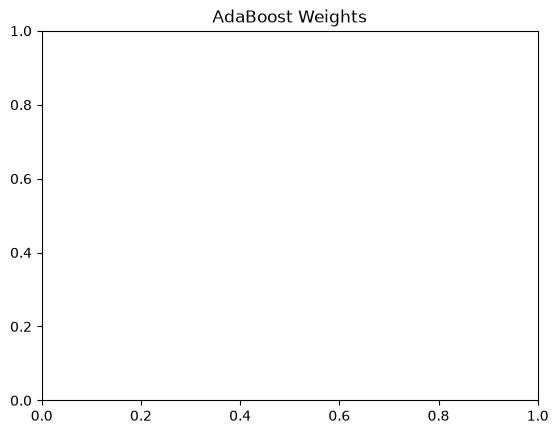

In [5]:
plt.title('AdaBoost Weights')
plt.show()
